# EDA de DataMarts Procesados — Validación Post-ETL y Análisis Q1–Q5 (PySpark SQL + Matplotlib)

**Objetivo:** Conectar directamente a los **4 DataMarts procesados en SQL Server**, registrarlos en **PySpark SQL** y verificar que todas las reglas de limpieza, homologación e integridad se cumplieron correctamente, además de explorar los resultados analíticos alineados a las **5 preguntas guía (Q1–Q5)** del Data Warehouse `DW_ProyectoEF`.

**DataMarts consultados en SQL Server:**
1. `DBDenunciasPoliciales.dm.DenunciasPoliciales` (`dm_denuncias`)
2. `DBPersonasDesaparecidas.dm.PersonasDesaparecidas` (`dm_desaparecidos`)
3. `DBProduccionPolicial.dm.ProduccionPolicial` (`dm_produccion`)
4. `DBVictimizacionConfianzaPNP.dm.VictimizacionConfianzaPNP` (`dm_victimizacion`)

> **Conexión parametrizable:** Por defecto apunta a `(localdb)\MSSQLLocalDB` con Autenticación de Windows; puedes cambiar `SQL_SERVER = "localhost"` en la primera celda o mediante la variable de entorno `SQL_SERVER`.
> Todas las métricas, tablas CSV y gráficas Matplotlib se exportan a `EDA/EDA-Datamarts/outputs/` para su presentación en **Streamlit**.

In [1]:
import os
import sys
import csv
import json
import tempfile
import shutil
from pathlib import Path
import pyodbc
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from pyspark.sql import SparkSession
from pyspark.sql.types import (
    StructType, StructField, IntegerType, DoubleType, StringType, BooleanType
)

# Asegurar que PySpark use exactamente el Python del entorno conda ciencia-de-datos
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

# Parámetro de conexión SQL Server (cambiar a "localhost" si se desea usar la instancia predeterminada)
SQL_SERVER = os.getenv("SQL_SERVER", r"(localdb)\MSSQLLocalDB")

# Detección automática del driver ODBC moderno de SQL Server
available_drivers = pyodbc.drivers()
ODBC_DRIVER = next(
    (d for d in ["ODBC Driver 18 for SQL Server", "ODBC Driver 17 for SQL Server"] if d in available_drivers),
    None,
)
assert ODBC_DRIVER is not None, f"No se encontró ODBC Driver 17/18 para SQL Server. Disponibles: {available_drivers}"

print("SQL_SERVER :", SQL_SERVER)
print("ODBC_DRIVER:", ODBC_DRIVER)

# Estilo Matplotlib
plt.rcParams.update({
    "figure.figsize": (11, 5),
    "figure.dpi": 130,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
})

# Rutas del proyecto
CWD = Path.cwd()
if (CWD / "Database").exists():
    PROJECT_ROOT = CWD
elif (CWD.parent.parent / "Database").exists():
    PROJECT_ROOT = CWD.parent.parent
else:
    PROJECT_ROOT = Path(r"c:\Users\rodry20x\Documents\Clases-UPN\Ciclo_2026-2\BigDATA\EF_Final")

OUT_DIR = PROJECT_ROOT / "EDA" / "EDA-Datamarts" / "outputs"
OUT_DIR.mkdir(parents=True, exist_ok=True)

spark = (
    SparkSession.builder
    .master("local[*]")
    .appName("EDA_DataMarts_EF_Final")
    .config("spark.ui.enabled", "false")
    .config("spark.sql.shuffle.partitions", "8")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
print("PySpark version:", spark.version)
print("OUT_DIR        :", OUT_DIR)

SQL_SERVER : (localdb)\MSSQLLocalDB
ODBC_DRIVER: ODBC Driver 18 for SQL Server


PySpark version: 4.2.0
OUT_DIR        : C:\Users\rodry20x\Documents\Clases-UPN\Ciclo_2026-2\BigDATA\EF_Final\EDA\EDA-Datamarts\outputs


## 1. Extracción desde SQL Server y Registro en PySpark SQL

Extraemos las 4 tablas `dm.*` desde SQL Server vía `pyodbc` (Autenticación de Windows) y las registramos como vistas temporales de **PySpark SQL** con esquemas explícitos para garantizar tipos exactos (`INT`, `DOUBLE`, `BOOLEAN`, `STRING`).

In [2]:
TMP_SQL_DIR = Path(tempfile.mkdtemp(prefix="ef_dm_spark_"))

def load_sql_to_spark(database: str, query: str, cols: list[str], schema: StructType, view_name: str):
    """Extrae desde SQL Server vía pyodbc a un CSV temporal UTF-8 y lo lee nativamente en PySpark JVM."""
    conn_str = (
        f"DRIVER={{{ODBC_DRIVER}}};"
        f"SERVER={SQL_SERVER};"
        f"DATABASE={database};"
        f"Trusted_Connection=yes;"
        f"TrustServerCertificate=yes;"
    )
    csv_path = TMP_SQL_DIR / f"{view_name}.csv"
    with pyodbc.connect(conn_str, timeout=15) as conn:
        cur = conn.cursor()
        cur.execute(query)
        with csv_path.open("w", newline="", encoding="utf-8") as fh:
            writer = csv.writer(fh)
            writer.writerow(cols)
            while True:
                batch = cur.fetchmany(20000)
                if not batch:
                    break
                writer.writerows(
                    ["" if v is None else ("true" if isinstance(v, bool) and v else ("false" if isinstance(v, bool) else v)) for v in row]
                    for row in batch
                )
    df = (
        spark.read
        .option("header", True)
        .option("encoding", "UTF-8")
        .option("nullValue", "")
        .schema(schema)
        .csv(str(csv_path))
    )
    df.createOrReplaceTempView(view_name)
    return df

# 1. DBDenunciasPoliciales
schema_d1 = StructType([
    StructField("anio_registro", IntegerType(), False),
    StructField("mes_registro", IntegerType(), False),
    StructField("fecha_hecho", StringType(), False),
    StructField("departamento", StringType(), False),
    StructField("provincia", StringType(), False),
    StructField("distrito", StringType(), False),
    StructField("ubigeo", StringType(), False),
    StructField("modalidad", StringType(), False),
    StructField("cantidad", IntegerType(), False),
    StructField("es_anio_parcial", BooleanType(), False),
])
df_dm_denuncias = load_sql_to_spark(
    "DBDenunciasPoliciales",
    """
    SELECT CAST(anio_registro AS INT), CAST(mes_registro AS INT),
           CONVERT(VARCHAR(10), fecha_hecho, 23),
           departamento, provincia, distrito, ubigeo, modalidad,
           CAST(cantidad AS INT), CAST(es_anio_parcial AS BIT)
    FROM dm.DenunciasPoliciales
    """,
    [f.name for f in schema_d1.fields],
    schema_d1,
    "dm_denuncias",
)

# 2. DBPersonasDesaparecidas
schema_d2 = StructType([
    StructField("anio_registro", IntegerType(), False),
    StructField("mes_registro", IntegerType(), False),
    StructField("fecha_hecho", StringType(), False),
    StructField("departamento", StringType(), False),
    StructField("provincia", StringType(), False),
    StructField("distrito", StringType(), False),
    StructField("ubigeo", StringType(), False),
    StructField("sexo", StringType(), True),
    StructField("rango_edad", StringType(), True),
    StructField("nacionalidad", StringType(), False),
    StructField("cantidad", IntegerType(), False),
    StructField("es_anio_parcial", BooleanType(), False),
])
df_dm_desaparecidos = load_sql_to_spark(
    "DBPersonasDesaparecidas",
    """
    SELECT CAST(anio_registro AS INT), CAST(mes_registro AS INT),
           CONVERT(VARCHAR(10), fecha_hecho, 23),
           departamento, provincia, distrito, ubigeo,
           sexo, rango_edad, nacionalidad,
           CAST(cantidad AS INT), CAST(es_anio_parcial AS BIT)
    FROM dm.PersonasDesaparecidas
    """,
    [f.name for f in schema_d2.fields],
    schema_d2,
    "dm_desaparecidos",
)

# 3. DBProduccionPolicial
schema_d3 = StructType([
    StructField("anio_registro", IntegerType(), False),
    StructField("mes_registro", IntegerType(), False),
    StructField("fecha_hecho", StringType(), False),
    StructField("variable", StringType(), False),
    StructField("unidad_medida", StringType(), False),
    StructField("dependencia", StringType(), False),
    StructField("dir_reg_fre", StringType(), False),
    StructField("valor", DoubleType(), False),
    StructField("es_anio_parcial", BooleanType(), False),
])
df_dm_produccion = load_sql_to_spark(
    "DBProduccionPolicial",
    """
    SELECT CAST(anio_registro AS INT), CAST(mes_registro AS INT),
           CONVERT(VARCHAR(10), fecha_hecho, 23),
           variable, unidad_medida, dependencia, dir_reg_fre,
           CAST(valor AS FLOAT), CAST(es_anio_parcial AS BIT)
    FROM dm.ProduccionPolicial
    """,
    [f.name for f in schema_d3.fields],
    schema_d3,
    "dm_produccion",
)

# 4. DBVictimizacionConfianzaPNP
schema_d4 = StructType([
    StructField("anio_registro", IntegerType(), False),
    StructField("fecha_referencia", StringType(), False),
    StructField("ambito", StringType(), False),
    StructField("cod_ubicacion", IntegerType(), False),
    StructField("departamento", StringType(), True),
    StructField("indicador", StringType(), False),
    StructField("clasif", IntegerType(), False),
    StructField("valor", DoubleType(), False),
    StructField("es_anio_parcial", BooleanType(), False),
])
df_dm_victimizacion = load_sql_to_spark(
    "DBVictimizacionConfianzaPNP",
    """
    SELECT CAST(anio_registro AS INT),
           CONVERT(VARCHAR(10), fecha_referencia, 23),
           ambito, CAST(cod_ubicacion AS INT), departamento,
           indicador, CAST(clasif AS INT),
           CAST(valor AS FLOAT), CAST(es_anio_parcial AS BIT)
    FROM dm.VictimizacionConfianzaPNP
    """,
    [f.name for f in schema_d4.fields],
    schema_d4,
    "dm_victimizacion",
)

# Cachear vistas en memoria Spark para acelerar las consultas SQL
spark.sql("CACHE TABLE dm_denuncias")
spark.sql("CACHE TABLE dm_desaparecidos")
spark.sql("CACHE TABLE dm_produccion")
spark.sql("CACHE TABLE dm_victimizacion")

resumen_dm = spark.sql("""
    SELECT '1. DBDenunciasPoliciales' AS datamart, COUNT(*) AS filas,
           MIN(anio_registro) AS anio_min, MAX(anio_registro) AS anio_max,
           SUM(CASE WHEN es_anio_parcial THEN 1 ELSE 0 END) AS filas_anio_parcial
    FROM dm_denuncias
    UNION ALL
    SELECT '2. DBPersonasDesaparecidas', COUNT(*),
           MIN(anio_registro), MAX(anio_registro),
           SUM(CASE WHEN es_anio_parcial THEN 1 ELSE 0 END)
    FROM dm_desaparecidos
    UNION ALL
    SELECT '3. DBProduccionPolicial', COUNT(*),
           MIN(anio_registro), MAX(anio_registro),
           SUM(CASE WHEN es_anio_parcial THEN 1 ELSE 0 END)
    FROM dm_produccion
    UNION ALL
    SELECT '4. DBVictimizacionConfianzaPNP', COUNT(*),
           MIN(anio_registro), MAX(anio_registro),
           SUM(CASE WHEN es_anio_parcial THEN 1 ELSE 0 END)
    FROM dm_victimizacion
""").toPandas()

resumen_dm.to_csv(OUT_DIR / "resumen_general_datamarts.csv", index=False, encoding="utf-8-sig")
display(resumen_dm)

,datamart,filas,anio_min,anio_max,filas_anio_parcial
0,1. DBDenunciasPoliciales,378187,2018,2026,37683
1,2. DBPersonasDesaparecidas,77331,2019,2025,0
2,3. DBProduccionPolicial,39096,2023,2026,8640
3,4. DBVictimizacionConfianzaPNP,1592,2013,2024,107


## 2. Auditoría de Calidad Post-ETL (PySpark SQL)

Verificamos objetivamente que **todos los problemas detectados en el EDA de Datos Crudos** hayan quedado corregidos en los 4 DataMarts:
- 0 duplicados por grano en los 4 DataMarts.
- 0 ubigeos con longitud diferente de 6 dígitos y 0 conflictos en `160801` y `150121`.
- Consistencia total de los 26 departamentos canónicos entre D1, D2 y D4 (`ambito = 'DEPARTAMENTO'`).
- Meses numéricos `1–12` en D1, D2 y D3; `unidad_medida` poblada en D3.
- `ambito = 'NACIONAL'` separado con `departamento IS NULL` y 0 códigos desalineados en D4.

In [3]:
auditoria_df = spark.sql("""
    SELECT 'D1: Ubigeos con longitud != 6' AS verificacion,
           SUM(CASE WHEN LENGTH(ubigeo) <> 6 THEN 1 ELSE 0 END) AS incidencias,
           CASE WHEN SUM(CASE WHEN LENGTH(ubigeo) <> 6 THEN 1 ELSE 0 END) = 0 THEN 'OK' ELSE 'FALLO' END AS estado
    FROM dm_denuncias
    UNION ALL
    SELECT 'D1: Duplicados por grano',
           COUNT(*) - COUNT(DISTINCT CONCAT_WS('|', anio_registro, mes_registro, ubigeo, modalidad)),
           CASE WHEN COUNT(*) = COUNT(DISTINCT CONCAT_WS('|', anio_registro, mes_registro, ubigeo, modalidad)) THEN 'OK' ELSE 'FALLO' END
    FROM dm_denuncias
    UNION ALL
    SELECT 'D1: Conflicto provincia en ubigeo 160801 (>1 nombre)',
           CASE WHEN COUNT(DISTINCT provincia) > 1 THEN COUNT(DISTINCT provincia) - 1 ELSE 0 END,
           CASE WHEN COUNT(DISTINCT provincia) <= 1 THEN 'OK' ELSE 'FALLO' END
    FROM dm_denuncias WHERE ubigeo = '160801'
    UNION ALL
    SELECT 'D2: Ubigeos con longitud != 6',
           SUM(CASE WHEN LENGTH(ubigeo) <> 6 THEN 1 ELSE 0 END),
           CASE WHEN SUM(CASE WHEN LENGTH(ubigeo) <> 6 THEN 1 ELSE 0 END) = 0 THEN 'OK' ELSE 'FALLO' END
    FROM dm_desaparecidos
    UNION ALL
    SELECT 'D2: Departamentos con tildes o CALLAO sin canonizar',
           SUM(CASE WHEN departamento IN ('JUNÍN','REGIÓN LIMA','HUÁNUCO','ÁNCASH','SAN MARTÍN','CALLAO') THEN 1 ELSE 0 END),
           CASE WHEN SUM(CASE WHEN departamento IN ('JUNÍN','REGIÓN LIMA','HUÁNUCO','ÁNCASH','SAN MARTÍN','CALLAO') THEN 1 ELSE 0 END) = 0 THEN 'OK' ELSE 'FALLO' END
    FROM dm_desaparecidos
    UNION ALL
    SELECT 'D2: Conflicto distrito en ubigeo 150121 (>1 nombre)',
           CASE WHEN COUNT(DISTINCT distrito) > 1 THEN COUNT(DISTINCT distrito) - 1 ELSE 0 END,
           CASE WHEN COUNT(DISTINCT distrito) <= 1 THEN 'OK' ELSE 'FALLO' END
    FROM dm_desaparecidos WHERE ubigeo = '150121'
    UNION ALL
    SELECT 'D2: Duplicados por grano',
           COUNT(*) - COUNT(DISTINCT CONCAT_WS('|', anio_registro, mes_registro, ubigeo, COALESCE(sexo,''), COALESCE(rango_edad,''), nacionalidad)),
           CASE WHEN COUNT(*) = COUNT(DISTINCT CONCAT_WS('|', anio_registro, mes_registro, ubigeo, COALESCE(sexo,''), COALESCE(rango_edad,''), nacionalidad)) THEN 'OK' ELSE 'FALLO' END
    FROM dm_desaparecidos
    UNION ALL
    SELECT 'D3: Meses fuera de rango numérico 1–12',
           SUM(CASE WHEN mes_registro < 1 OR mes_registro > 12 THEN 1 ELSE 0 END),
           CASE WHEN SUM(CASE WHEN mes_registro < 1 OR mes_registro > 12 THEN 1 ELSE 0 END) = 0 THEN 'OK' ELSE 'FALLO' END
    FROM dm_produccion
    UNION ALL
    SELECT 'D3: Filas sin unidad_medida o con Región con tilde',
           SUM(CASE WHEN unidad_medida IS NULL OR TRIM(unidad_medida) = '' OR dir_reg_fre = 'Región' THEN 1 ELSE 0 END),
           CASE WHEN SUM(CASE WHEN unidad_medida IS NULL OR TRIM(unidad_medida) = '' OR dir_reg_fre = 'Región' THEN 1 ELSE 0 END) = 0 THEN 'OK' ELSE 'FALLO' END
    FROM dm_produccion
    UNION ALL
    SELECT 'D3: Duplicados por grano',
           COUNT(*) - COUNT(DISTINCT CONCAT_WS('|', anio_registro, mes_registro, dependencia, variable)),
           CASE WHEN COUNT(*) = COUNT(DISTINCT CONCAT_WS('|', anio_registro, mes_registro, dependencia, variable)) THEN 'OK' ELSE 'FALLO' END
    FROM dm_produccion
    UNION ALL
    SELECT 'D4: Incoherencia ambito=NACIONAL vs departamento/cod_ubicacion',
           SUM(CASE WHEN (ambito = 'NACIONAL' AND (departamento IS NOT NULL OR cod_ubicacion <> 0))
                      OR (ambito = 'DEPARTAMENTO' AND (departamento IS NULL OR cod_ubicacion = 0)) THEN 1 ELSE 0 END),
           CASE WHEN SUM(CASE WHEN (ambito = 'NACIONAL' AND (departamento IS NOT NULL OR cod_ubicacion <> 0))
                      OR (ambito = 'DEPARTAMENTO' AND (departamento IS NULL OR cod_ubicacion = 0)) THEN 1 ELSE 0 END) = 0 THEN 'OK' ELSE 'FALLO' END
    FROM dm_victimizacion
    UNION ALL
    SELECT 'D4: Departamentos con múltiples cod_ubicacion (desalineados)',
           (SELECT COUNT(*) FROM (SELECT departamento FROM dm_victimizacion WHERE ambito='DEPARTAMENTO' GROUP BY departamento HAVING COUNT(DISTINCT cod_ubicacion) > 1) t),
           CASE WHEN (SELECT COUNT(*) FROM (SELECT departamento FROM dm_victimizacion WHERE ambito='DEPARTAMENTO' GROUP BY departamento HAVING COUNT(DISTINCT cod_ubicacion) > 1) t) = 0 THEN 'OK' ELSE 'FALLO' END
    FROM (SELECT 1) dummy
    UNION ALL
    SELECT 'Cruce D1–D2–D4: Departamentos no coincidentes entre DataMarts',
           (SELECT COUNT(*) FROM (
                SELECT DISTINCT departamento FROM dm_denuncias
                EXCEPT
                SELECT DISTINCT departamento FROM dm_victimizacion WHERE ambito = 'DEPARTAMENTO'
           ) x) +
           (SELECT COUNT(*) FROM (
                SELECT DISTINCT departamento FROM dm_desaparecidos
                EXCEPT
                SELECT DISTINCT departamento FROM dm_denuncias
           ) y),
           CASE WHEN (
                (SELECT COUNT(*) FROM (
                    SELECT DISTINCT departamento FROM dm_denuncias
                    EXCEPT
                    SELECT DISTINCT departamento FROM dm_victimizacion WHERE ambito = 'DEPARTAMENTO'
                ) x) +
                (SELECT COUNT(*) FROM (
                    SELECT DISTINCT departamento FROM dm_desaparecidos
                    EXCEPT
                    SELECT DISTINCT departamento FROM dm_denuncias
                ) y)
           ) = 0 THEN 'OK' ELSE 'FALLO' END
    FROM (SELECT 1) dummy2
""").toPandas()

auditoria_df.to_csv(OUT_DIR / "auditoria_calidad_datamarts.csv", index=False, encoding="utf-8-sig")
display(auditoria_df)
assert (auditoria_df["estado"] == "OK").all(), "Falló al menos una validación de calidad post-ETL"
print("Todas las validaciones de calidad post-ETL aprobaron (100% OK).")

,verificacion,incidencias,estado
0,D1: Ubigeos con longitud != 6,0,OK
1,D1: Duplicados por grano,0,OK
2,D1: Conflicto provincia en ubigeo 160801 (>1 n...,0,OK
3,D2: Ubigeos con longitud != 6,0,OK
4,D2: Departamentos con tildes o CALLAO sin cano...,0,OK
5,D2: Conflicto distrito en ubigeo 150121 (>1 no...,0,OK
6,D2: Duplicados por grano,0,OK
7,D3: Meses fuera de rango numérico 1–12,0,OK
8,D3: Filas sin unidad_medida o con Región con t...,0,OK
9,D3: Duplicados por grano,0,OK


Todas las validaciones de calidad post-ETL aprobaron (100% OK).


## 3. Análisis Post-ETL — Q1: Denuncias Policiales (2018–2025, `es_anio_parcial = 0`)

Evaluamos la evolución anual, la estacionalidad mensual (meses 1–12) y las modalidades delictivas más recurrentes excluyendo `2026` parcial.

,anio,filas,total_denuncias,promedio_mensual
0,2018,32879,771473,64289.4
1,2019,37877,852706,71058.8
2,2020,37651,646083,53840.3
3,2021,43165,754041,62836.8
4,2022,46199,876489,73040.8
5,2023,48124,1042205,86850.4
6,2024,48235,1017082,84756.8
7,2025,46374,906527,75543.9


,modalidad,total_denuncias,pct_participacion
0,Otros,2483096,36.16
1,Violencia contra la mujer e integrantes,2023213,29.46
2,Hurto,1367670,19.92
3,Robo,685218,9.98
4,Estafa,197256,2.87
5,Extorsión,100759,1.47
6,Secuestro,9394,0.14


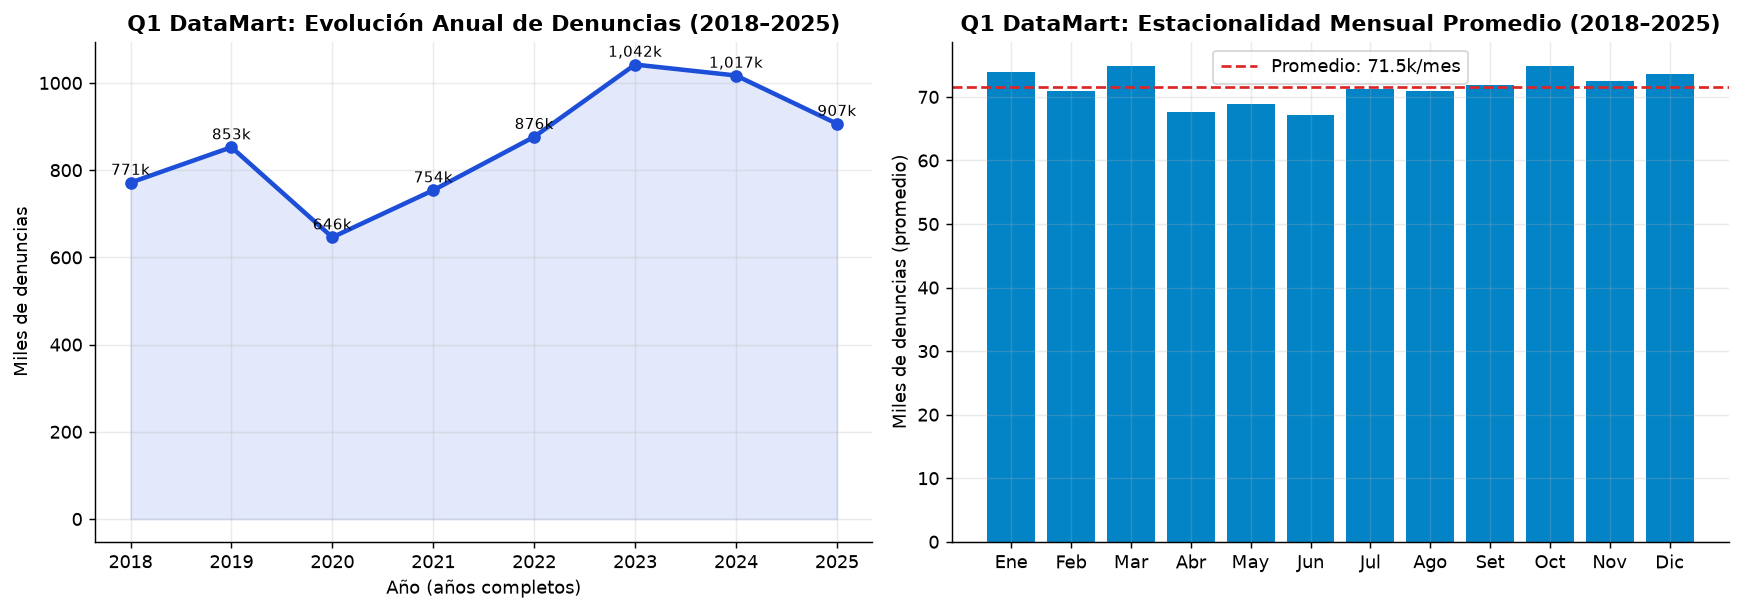

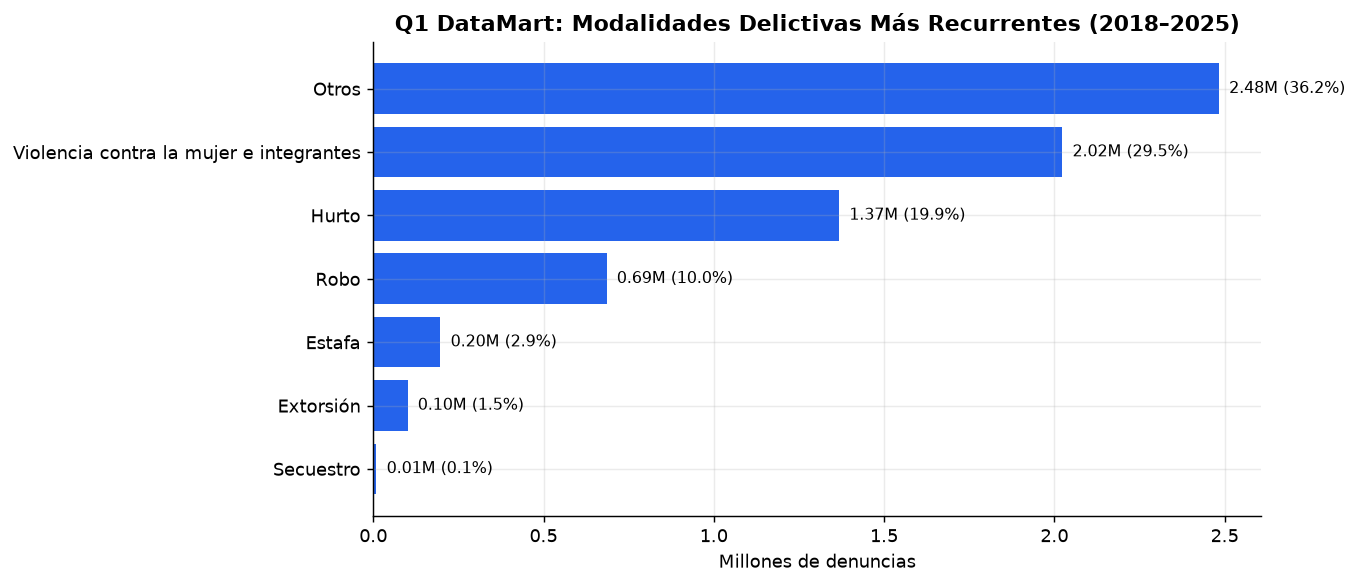

In [4]:
q1_anual = spark.sql("""
    SELECT anio_registro AS anio,
           COUNT(*) AS filas,
           SUM(cantidad) AS total_denuncias,
           ROUND(SUM(cantidad) / 12.0, 1) AS promedio_mensual
    FROM dm_denuncias
    WHERE es_anio_parcial = FALSE
    GROUP BY anio_registro
    ORDER BY anio
""").toPandas()

q1_estacionalidad = spark.sql("""
    SELECT mes_registro AS mes,
           ROUND(AVG(denuncias_mes), 1) AS promedio_denuncias_mes,
           SUM(denuncias_mes) AS acumulado_mes
    FROM (
        SELECT anio_registro, mes_registro, SUM(cantidad) AS denuncias_mes
        FROM dm_denuncias
        WHERE es_anio_parcial = FALSE
        GROUP BY anio_registro, mes_registro
    ) t
    GROUP BY mes_registro
    ORDER BY mes
""").toPandas()

q1_modalidad = spark.sql("""
    SELECT modalidad,
           SUM(cantidad) AS total_denuncias,
           ROUND(100.0 * SUM(cantidad) / SUM(SUM(cantidad)) OVER (), 2) AS pct_participacion
    FROM dm_denuncias
    WHERE es_anio_parcial = FALSE
    GROUP BY modalidad
    ORDER BY total_denuncias DESC
""").toPandas()

q1_anual.to_csv(OUT_DIR / "q1_denuncias_anual.csv", index=False, encoding="utf-8-sig")
q1_estacionalidad.to_csv(OUT_DIR / "q1_denuncias_estacionalidad.csv", index=False, encoding="utf-8-sig")
q1_modalidad.to_csv(OUT_DIR / "q1_denuncias_modalidad.csv", index=False, encoding="utf-8-sig")

display(q1_anual)
display(q1_modalidad)

# Gráfica 1: Evolución anual y estacionalidad mensual (Q1)
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))

axes[0].plot(q1_anual["anio"], q1_anual["total_denuncias"] / 1e3, marker="o", linewidth=2.5, color="#1D4ED8")
axes[0].fill_between(q1_anual["anio"], q1_anual["total_denuncias"] / 1e3, alpha=0.12, color="#1D4ED8")
axes[0].set_title("Q1 DataMart: Evolución Anual de Denuncias (2018–2025)", fontweight="bold")
axes[0].set_xlabel("Año (años completos)")
axes[0].set_ylabel("Miles de denuncias")
for x_v, y_v in zip(q1_anual["anio"], q1_anual["total_denuncias"] / 1e3):
    axes[0].text(x_v, y_v + 18, f"{y_v:,.0f}k", ha="center", fontsize=8.5)

meses_lbl = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Set", "Oct", "Nov", "Dic"]
axes[1].bar(meses_lbl, q1_estacionalidad["promedio_denuncias_mes"] / 1e3, color="#0284C7")
prom_global = q1_estacionalidad["promedio_denuncias_mes"].mean() / 1e3
axes[1].axhline(prom_global, color="#DC2626", linestyle="--", label=f"Promedio: {prom_global:.1f}k/mes")
axes[1].set_title("Q1 DataMart: Estacionalidad Mensual Promedio (2018–2025)", fontweight="bold")
axes[1].set_ylabel("Miles de denuncias (promedio)")
axes[1].legend()

plt.tight_layout()
plt.savefig(OUT_DIR / "01_dm_q1_evolucion_estacionalidad.png", dpi=150, bbox_inches="tight")
plt.show()

# Gráfica 2: Modalidades más recurrentes
fig, ax = plt.subplots(figsize=(10.5, 4.6))
df_m = q1_modalidad.sort_values("total_denuncias", ascending=True)
bars = ax.barh(df_m["modalidad"], df_m["total_denuncias"] / 1e6, color="#2563EB")
ax.set_title("Q1 DataMart: Modalidades Delictivas Más Recurrentes (2018–2025)", fontweight="bold")
ax.set_xlabel("Millones de denuncias")
for b, pct in zip(bars, df_m["pct_participacion"]):
    w = b.get_width()
    ax.text(w + 0.03, b.get_y() + b.get_height()/2, f"{w:.2f}M ({pct:.1f}%)", va="center", fontsize=9)
plt.tight_layout()
plt.savefig(OUT_DIR / "02_dm_q1_modalidades.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Análisis Post-ETL — Q2: Personas Desaparecidas (2019–2025)

Analizamos el perfil demográfico limpio por sexo y rango de edad, cuantificando los casos de **menores de 18 años** (`0-5 AÑOS`, `6-11 AÑOS`, `12-17 AÑOS`) y transparentando los registros con `NULL` preservados.

,total_casos,menores_18,pct_menores_18,casos_femenino,casos_masculino,casos_sexo_null,casos_edad_null
0,142374,81262,57.08,86922,55362,90,1357


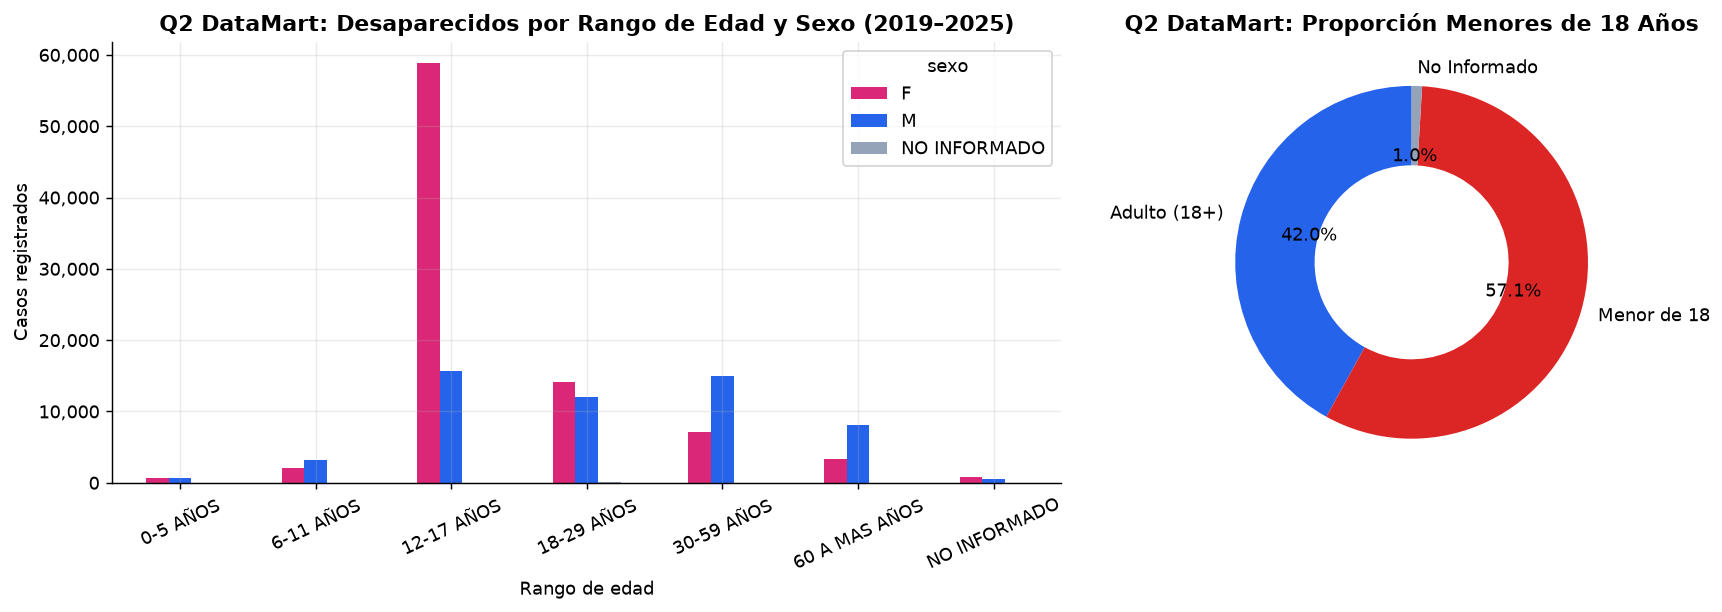

In [5]:
q2_perfil = spark.sql("""
    SELECT COALESCE(rango_edad, 'NO INFORMADO') AS rango_edad,
           COALESCE(sexo, 'NO INFORMADO') AS sexo,
           CASE WHEN rango_edad IN ('0-5 AÑOS', '6-11 AÑOS', '12-17 AÑOS') THEN 'Menor de 18'
                WHEN rango_edad IS NULL THEN 'No Informado'
                ELSE 'Adulto (18+)' END AS grupo_etario,
           SUM(cantidad) AS casos
    FROM dm_desaparecidos
    GROUP BY COALESCE(rango_edad, 'NO INFORMADO'),
             COALESCE(sexo, 'NO INFORMADO'),
             CASE WHEN rango_edad IN ('0-5 AÑOS', '6-11 AÑOS', '12-17 AÑOS') THEN 'Menor de 18'
                  WHEN rango_edad IS NULL THEN 'No Informado'
                  ELSE 'Adulto (18+)' END
""").toPandas()

q2_kpis = spark.sql("""
    SELECT SUM(cantidad) AS total_casos,
           SUM(CASE WHEN rango_edad IN ('0-5 AÑOS', '6-11 AÑOS', '12-17 AÑOS') THEN cantidad ELSE 0 END) AS menores_18,
           ROUND(100.0 * SUM(CASE WHEN rango_edad IN ('0-5 AÑOS', '6-11 AÑOS', '12-17 AÑOS') THEN cantidad ELSE 0 END) / SUM(cantidad), 2) AS pct_menores_18,
           SUM(CASE WHEN sexo = 'F' THEN cantidad ELSE 0 END) AS casos_femenino,
           SUM(CASE WHEN sexo = 'M' THEN cantidad ELSE 0 END) AS casos_masculino,
           SUM(CASE WHEN sexo IS NULL THEN cantidad ELSE 0 END) AS casos_sexo_null,
           SUM(CASE WHEN rango_edad IS NULL THEN cantidad ELSE 0 END) AS casos_edad_null
    FROM dm_desaparecidos
""").toPandas()

q2_perfil.to_csv(OUT_DIR / "q2_desaparecidos_perfil.csv", index=False, encoding="utf-8-sig")
display(q2_kpis)

# Gráfica 3: Perfil por rango de edad y sexo + proporción menores 18
orden = ["0-5 AÑOS", "6-11 AÑOS", "12-17 AÑOS", "18-29 AÑOS", "30-59 AÑOS", "60 A MAS AÑOS", "NO INFORMADO"]
piv = q2_perfil.pivot_table(index="rango_edad", columns="sexo", values="casos", aggfunc="sum", fill_value=0)
piv = piv.reindex([e for e in orden if e in piv.index])

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8), gridspec_kw={"width_ratios": [2, 1]})
piv.plot(kind="bar", ax=axes[0], color={"F": "#DB2777", "M": "#2563EB", "NO INFORMADO": "#94A3B8"})
axes[0].set_title("Q2 DataMart: Desaparecidos por Rango de Edad y Sexo (2019–2025)", fontweight="bold")
axes[0].set_xlabel("Rango de edad")
axes[0].set_ylabel("Casos registrados")
axes[0].yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
axes[0].tick_params(axis="x", rotation=25)

grp = q2_perfil.groupby("grupo_etario")["casos"].sum()
axes[1].pie(
    grp.values,
    labels=grp.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=["#2563EB", "#DC2626", "#94A3B8"],
    wedgeprops={"width": 0.45},
)
axes[1].set_title("Q2 DataMart: Proporción Menores de 18 Años", fontweight="bold")

plt.tight_layout()
plt.savefig(OUT_DIR / "03_dm_q2_desaparecidos_perfil.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Análisis Post-ETL — Q3: Producción Policial (2023–2025, `es_anio_parcial = 0`)

Gracias a la nueva columna derivada `unidad_medida`, consultamos con **PySpark SQL** cada magnitud por separado sin mezclar kilos, soles, personas ni operativos.

,anio,operativos,detenidos,bandas_desarticuladas,kilos_droga,dinero_incautado_soles,contrabando_soles
0,2023,1269937.0,338662.0,11679.0,119345.96,11704529.39,3.427823e+08
1,2024,1110260.0,362825.0,13023.0,217572.73,25880605.54,8.384907e+08
2,2025,1123761.0,360152.0,13450.0,181875.86,16289794.79,4.505432e+08


,unidad_medida,variables,filas,total_unidad
0,ENVOLTORIO,1,1692,4.445890e+05
1,ENVOLTORIOS,2,3384,6.623509e+06
2,KILOS,3,5076,5.187945e+05
3,OPERATIVOS,1,1692,3.503958e+06
4,PAPELETAS,1,1692,3.289357e+06
5,PERSONAS,4,6768,1.254351e+06
6,SOLES,1,1692,5.387493e+07
7,SOLES (VALORIZACION),1,1692,1.631816e+09
8,UNIDADES,4,6768,7.812000e+04


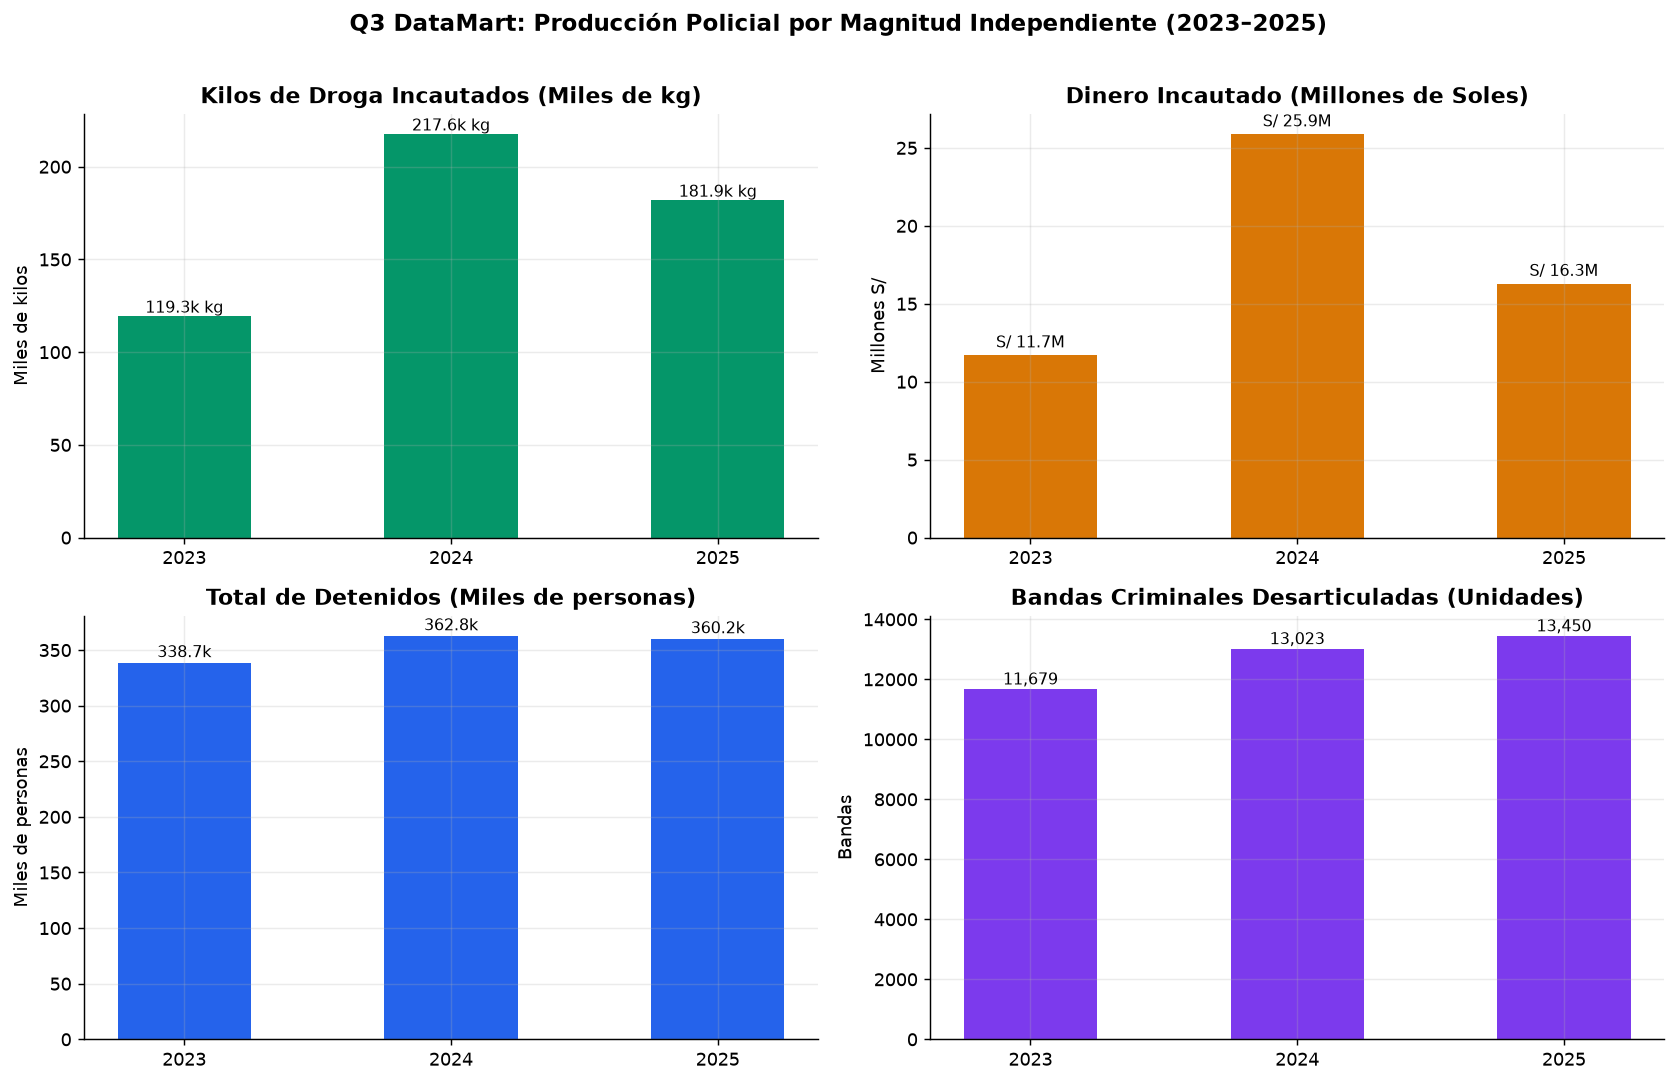

In [6]:
q3_anual = spark.sql("""
    SELECT anio_registro AS anio,
           ROUND(SUM(CASE WHEN variable = 'OPERATIVOS' THEN valor ELSE 0 END), 0) AS operativos,
           ROUND(SUM(CASE WHEN variable IN ('DETENIDOS DIVERSOS DELITOS (PERUANOS)', 'DETENIDOS DIVERSOS DELITOS (EXTRANJEROS)', 'DETENIDOS POR REQUISITORIADO') THEN valor ELSE 0 END), 0) AS detenidos,
           ROUND(SUM(CASE WHEN variable = 'BANDAS CRIMINALES DESARTICULADAS' THEN valor ELSE 0 END), 0) AS bandas_desarticuladas,
           ROUND(SUM(CASE WHEN unidad_medida = 'KILOS' THEN valor ELSE 0 END), 2) AS kilos_droga,
           ROUND(SUM(CASE WHEN variable = 'DINERO INCAUTADO (SOLES)' THEN valor ELSE 0 END), 2) AS dinero_incautado_soles,
           ROUND(SUM(CASE WHEN variable = 'CONTRABANDO (VALORIZACION)' THEN valor ELSE 0 END), 2) AS contrabando_soles
    FROM dm_produccion
    WHERE es_anio_parcial = FALSE
    GROUP BY anio_registro
    ORDER BY anio
""").toPandas()

q3_por_unidad = spark.sql("""
    SELECT unidad_medida,
           COUNT(DISTINCT variable) AS variables,
           COUNT(*) AS filas,
           ROUND(SUM(valor), 2) AS total_unidad
    FROM dm_produccion
    WHERE es_anio_parcial = FALSE
    GROUP BY unidad_medida
    ORDER BY unidad_medida
""").toPandas()

q3_anual.to_csv(OUT_DIR / "q3_produccion_anual.csv", index=False, encoding="utf-8-sig")
q3_por_unidad.to_csv(OUT_DIR / "q3_produccion_unidades.csv", index=False, encoding="utf-8-sig")

display(q3_anual)
display(q3_por_unidad)

# Gráfica 4: Kilos de droga, Dinero incautado, Detenidos y Bandas (ejes independientes)
fig, axes = plt.subplots(2, 2, figsize=(13, 8.2))
anios_str = q3_anual["anio"].astype(str)

b1 = axes[0, 0].bar(anios_str, q3_anual["kilos_droga"] / 1e3, color="#059669", width=0.5)
axes[0, 0].set_title("Kilos de Droga Incautados (Miles de kg)", fontweight="bold")
axes[0, 0].set_ylabel("Miles de kilos")
for b in b1:
    axes[0, 0].text(b.get_x() + b.get_width()/2, b.get_height() + 2, f"{b.get_height():,.1f}k kg", ha="center", fontsize=9)

b2 = axes[0, 1].bar(anios_str, q3_anual["dinero_incautado_soles"] / 1e6, color="#D97706", width=0.5)
axes[0, 1].set_title("Dinero Incautado (Millones de Soles)", fontweight="bold")
axes[0, 1].set_ylabel("Millones S/")
for b in b2:
    axes[0, 1].text(b.get_x() + b.get_width()/2, b.get_height() + 0.5, f"S/ {b.get_height():,.1f}M", ha="center", fontsize=9)

b3 = axes[1, 0].bar(anios_str, q3_anual["detenidos"] / 1e3, color="#2563EB", width=0.5)
axes[1, 0].set_title("Total de Detenidos (Miles de personas)", fontweight="bold")
axes[1, 0].set_ylabel("Miles de personas")
for b in b3:
    axes[1, 0].text(b.get_x() + b.get_width()/2, b.get_height() + 5, f"{b.get_height():,.1f}k", ha="center", fontsize=9)

b4 = axes[1, 1].bar(anios_str, q3_anual["bandas_desarticuladas"], color="#7C3AED", width=0.5)
axes[1, 1].set_title("Bandas Criminales Desarticuladas (Unidades)", fontweight="bold")
axes[1, 1].set_ylabel("Bandas")
for b in b4:
    axes[1, 1].text(b.get_x() + b.get_width()/2, b.get_height() + 150, f"{b.get_height():,.0f}", ha="center", fontsize=9)

plt.suptitle("Q3 DataMart: Producción Policial por Magnitud Independiente (2023–2025)", fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(OUT_DIR / "04_dm_q3_produccion_policial.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Análisis Post-ETL — Q4: Victimización y Confianza PNP (2014–2024)

Filtramos `ambito = 'DEPARTAMENTO'` y `es_anio_parcial = FALSE` (excluyendo 2013 incompleto), calculando **promedios porcentuales** (nunca sumas de porcentajes) y comparando contra el referente `ambito = 'NACIONAL'`.

,departamento,prom_inseguridad_pct,prom_confianza_pnp_pct,prom_victimizacion_pct,inseguridad_2024_pct,confianza_2024_pct
0,PUNO,66.60,6.69,34.58,76.7,7.6
1,MADRE DE DIOS,66.21,10.05,28.99,74.4,7.2
2,LIMA METROPOLITANA,59.86,21.63,29.77,61.2,17.7
3,TACNA,58.91,16.67,33.34,60.7,16.2
4,PROV. CONST. DEL CALLAO,58.69,22.24,27.52,60.8,20.0
5,LAMBAYEQUE,58.44,23.61,16.47,56.0,17.2
6,ICA,57.75,21.32,19.22,64.6,20.9
7,AREQUIPA,57.03,20.81,26.70,65.3,18.4
8,PIURA,56.27,25.19,20.59,61.4,23.1
9,CUSCO,54.16,15.85,34.09,49.8,13.9


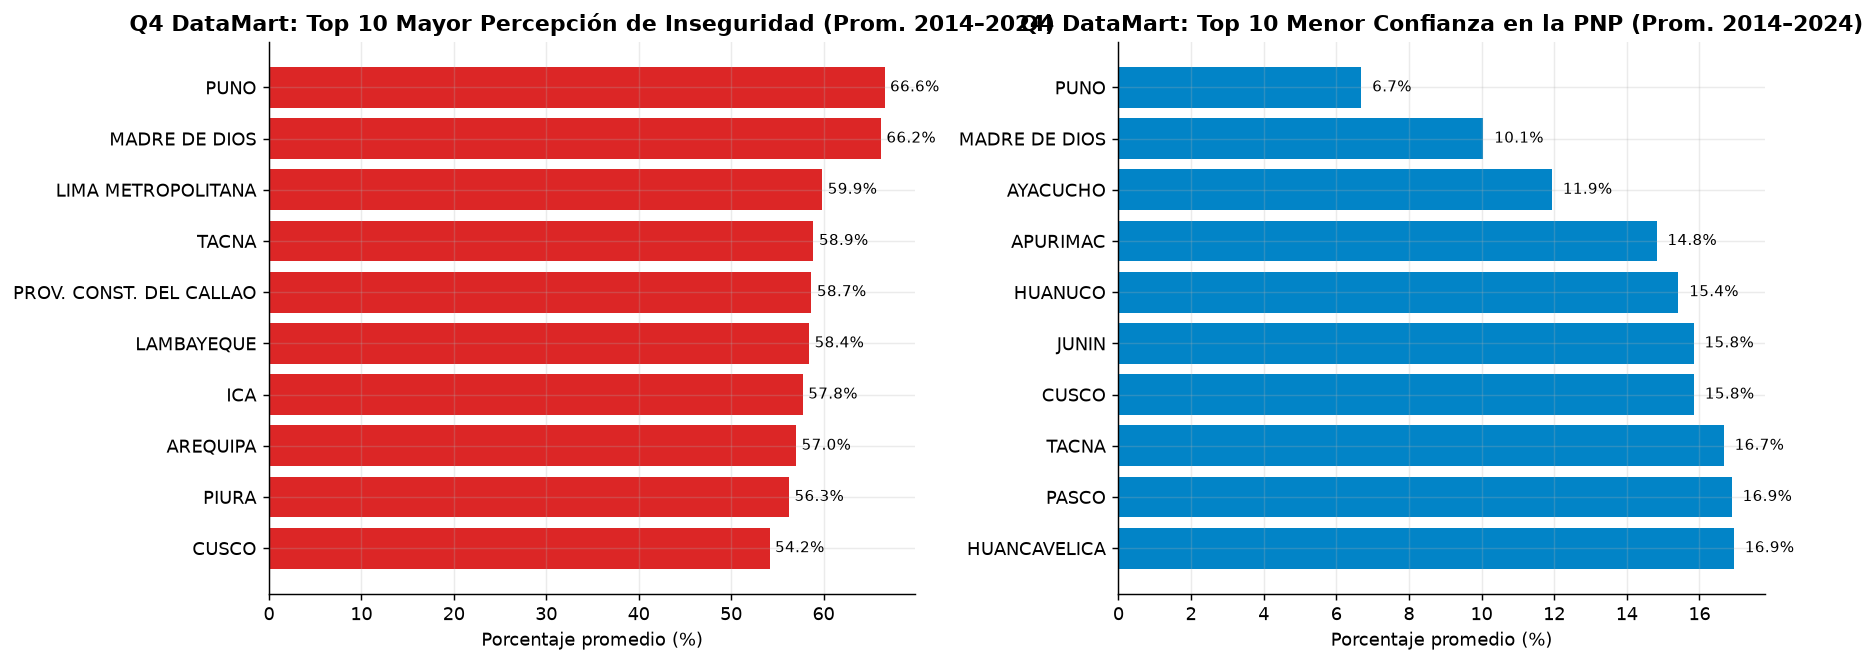

In [7]:
q4_dptos = spark.sql("""
    SELECT departamento,
           ROUND(AVG(CASE WHEN indicador LIKE '%PERCEPCIÓN DE INSEGURIDAD%' THEN valor END), 2) AS prom_inseguridad_pct,
           ROUND(AVG(CASE WHEN indicador = 'PORCENTAJE DE CONFIANZA EN LA PNP' THEN valor END), 2) AS prom_confianza_pnp_pct,
           ROUND(AVG(CASE WHEN indicador = 'PORCENTAJE DE VICTIMIZACIÓN' THEN valor END), 2) AS prom_victimizacion_pct,
           ROUND(MAX(CASE WHEN anio_registro = 2024 AND indicador LIKE '%PERCEPCIÓN DE INSEGURIDAD%' THEN valor END), 1) AS inseguridad_2024_pct,
           ROUND(MAX(CASE WHEN anio_registro = 2024 AND indicador = 'PORCENTAJE DE CONFIANZA EN LA PNP' THEN valor END), 1) AS confianza_2024_pct
    FROM dm_victimizacion
    WHERE ambito = 'DEPARTAMENTO'
      AND es_anio_parcial = FALSE
    GROUP BY departamento
    ORDER BY prom_inseguridad_pct DESC
""").toPandas()

q4_nacional = spark.sql("""
    SELECT anio_registro AS anio,
           MAX(CASE WHEN indicador LIKE '%PERCEPCIÓN DE INSEGURIDAD%' THEN valor END) AS inseguridad_nac_pct,
           MAX(CASE WHEN indicador = 'PORCENTAJE DE CONFIANZA EN LA PNP' THEN valor END) AS confianza_nac_pct,
           MAX(CASE WHEN indicador = 'PORCENTAJE DE VICTIMIZACIÓN' THEN valor END) AS victimizacion_nac_pct
    FROM dm_victimizacion
    WHERE ambito = 'NACIONAL'
      AND es_anio_parcial = FALSE
    GROUP BY anio_registro
    ORDER BY anio
""").toPandas()

q4_dptos.to_csv(OUT_DIR / "q4_victimizacion_departamentos.csv", index=False, encoding="utf-8-sig")
q4_nacional.to_csv(OUT_DIR / "q4_victimizacion_nacional.csv", index=False, encoding="utf-8-sig")

display(q4_dptos.head(10))

# Gráfica 5: Top 10 mayor inseguridad, Top 10 menor confianza y dispersión
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

top_inseg = q4_dptos.sort_values("prom_inseguridad_pct", ascending=False).head(10).sort_values("prom_inseguridad_pct")
b1 = axes[0].barh(top_inseg["departamento"], top_inseg["prom_inseguridad_pct"], color="#DC2626")
axes[0].set_title("Q4 DataMart: Top 10 Mayor Percepción de Inseguridad (Prom. 2014–2024)", fontweight="bold")
axes[0].set_xlabel("Porcentaje promedio (%)")
for b in b1:
    axes[0].text(b.get_width() + 0.6, b.get_y() + b.get_height()/2, f"{b.get_width():.1f}%", va="center", fontsize=8.5)

top_desconf = q4_dptos.sort_values("prom_confianza_pnp_pct", ascending=True).head(10).sort_values("prom_confianza_pnp_pct", ascending=False)
b2 = axes[1].barh(top_desconf["departamento"], top_desconf["prom_confianza_pnp_pct"], color="#0284C7")
axes[1].set_title("Q4 DataMart: Top 10 Menor Confianza en la PNP (Prom. 2014–2024)", fontweight="bold")
axes[1].set_xlabel("Porcentaje promedio (%)")
for b in b2:
    axes[1].text(b.get_width() + 0.3, b.get_y() + b.get_height()/2, f"{b.get_width():.1f}%", va="center", fontsize=8.5)

plt.tight_layout()
plt.savefig(OUT_DIR / "05_dm_q4_victimizacion_rankings.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Análisis Post-ETL — Q5: Cruce Multi-DataMart por Departamento y Año (2019–2025)

Demostramos que los nombres canónicos de `departamento` y los años homologados permiten cruzar directamente `dm_denuncias`, `dm_desaparecidos` y `dm_victimizacion` en **PySpark SQL** sin pérdida de registros.

,departamento,denuncias_2019_2025,desaparecidos_2019_2025,ratio_denuncias_por_desaparecido,inseguridad_prom_pct,confianza_pnp_prom_pct
0,LIMA METROPOLITANA,2121986,46848,45.30,58.98,24.05
1,AREQUIPA,419738,7864,53.37,56.17,20.65
2,LAMBAYEQUE,354557,7149,49.60,55.25,25.78
3,LA LIBERTAD,321484,5415,59.37,50.20,20.70
4,PIURA,308544,5543,55.66,53.72,26.33
5,JUNIN,256195,8254,31.04,52.07,17.50
6,CUSCO,249226,8604,28.97,50.53,17.48
7,PROV. CONST. DEL CALLAO,223220,5309,42.05,56.37,25.45
8,ICA,221165,3384,65.36,53.53,23.55
9,ANCASH,204590,3736,54.76,29.97,21.02


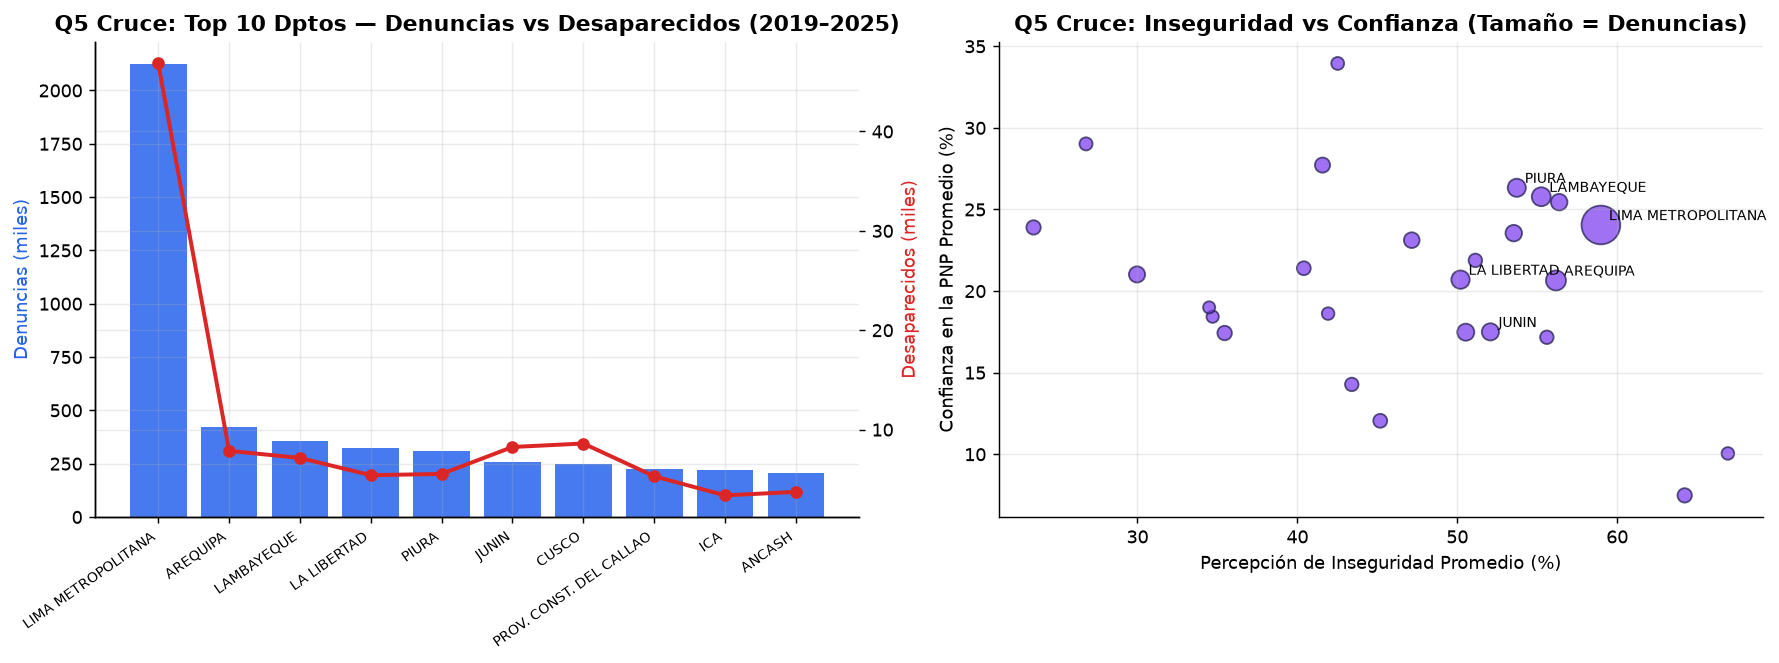

In [8]:
q5_cruzado = spark.sql("""
    WITH den AS (
        SELECT departamento, SUM(cantidad) AS denuncias_2019_2025
        FROM dm_denuncias
        WHERE anio_registro BETWEEN 2019 AND 2025
        GROUP BY departamento
    ),
    des AS (
        SELECT departamento, SUM(cantidad) AS desaparecidos_2019_2025
        FROM dm_desaparecidos
        WHERE anio_registro BETWEEN 2019 AND 2025
        GROUP BY departamento
    ),
    vic AS (
        SELECT departamento,
               ROUND(AVG(CASE WHEN indicador LIKE '%PERCEPCIÓN DE INSEGURIDAD%' THEN valor END), 2) AS inseguridad_prom_pct,
               ROUND(AVG(CASE WHEN indicador = 'PORCENTAJE DE CONFIANZA EN LA PNP' THEN valor END), 2) AS confianza_pnp_prom_pct
        FROM dm_victimizacion
        WHERE ambito = 'DEPARTAMENTO'
          AND anio_registro BETWEEN 2019 AND 2024
        GROUP BY departamento
    )
    SELECT den.departamento,
           den.denuncias_2019_2025,
           des.desaparecidos_2019_2025,
           ROUND(den.denuncias_2019_2025 / NULLIF(des.desaparecidos_2019_2025, 0), 2) AS ratio_denuncias_por_desaparecido,
           vic.inseguridad_prom_pct,
           vic.confianza_pnp_prom_pct
    FROM den
    JOIN des ON den.departamento = des.departamento
    JOIN vic ON den.departamento = vic.departamento
    ORDER BY den.denuncias_2019_2025 DESC
""").toPandas()

q5_cruzado.to_csv(OUT_DIR / "q5_cruzado_departamentos.csv", index=False, encoding="utf-8-sig")
display(q5_cruzado.head(10))

# Gráfica 6: Cruce Top 10 Departamentos (Denuncias vs Desaparecidos) + Dispersión Inseguridad vs Confianza
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

top10 = q5_cruzado.head(10)
x = range(len(top10))
ax1 = axes[0]
ax2 = ax1.twinx()
ax1.bar(x, top10["denuncias_2019_2025"] / 1e3, color="#2563EB", alpha=0.85, label="Denuncias (miles)")
ax2.plot(x, top10["desaparecidos_2019_2025"] / 1e3, color="#DC2626", marker="o", linewidth=2.2, label="Desaparecidos (miles)")
ax1.set_xticks(x)
ax1.set_xticklabels(top10["departamento"], rotation=35, ha="right", fontsize=8)
ax1.set_ylabel("Denuncias (miles)", color="#2563EB")
ax2.set_ylabel("Desaparecidos (miles)", color="#DC2626")
ax1.set_title("Q5 Cruce: Top 10 Dptos — Denuncias vs Desaparecidos (2019–2025)", fontweight="bold")
ax2.spines["top"].set_visible(False)

axes[1].scatter(
    q5_cruzado["inseguridad_prom_pct"],
    q5_cruzado["confianza_pnp_prom_pct"],
    s=(q5_cruzado["denuncias_2019_2025"] / q5_cruzado["denuncias_2019_2025"].max()) * 420 + 40,
    alpha=0.72,
    color="#7C3AED",
    edgecolors="#1E1B4B",
)
for _, r in q5_cruzado.head(6).iterrows():
    axes[1].annotate(r["departamento"], (r["inseguridad_prom_pct"] + 0.5, r["confianza_pnp_prom_pct"] + 0.3), fontsize=7.5)
axes[1].set_xlabel("Percepción de Inseguridad Promedio (%)")
axes[1].set_ylabel("Confianza en la PNP Promedio (%)")
axes[1].set_title("Q5 Cruce: Inseguridad vs Confianza (Tamaño = Denuncias)", fontweight="bold")

plt.tight_layout()
plt.savefig(OUT_DIR / "06_dm_q5_cruzado_departamentos.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Exportación de Resultados Post-ETL para Streamlit y Comparativa

Exportamos `resumen_datamarts.json` en `EDA/EDA-Datamarts/outputs/` con todas las métricas verificadas para las apps de **Streamlit**.

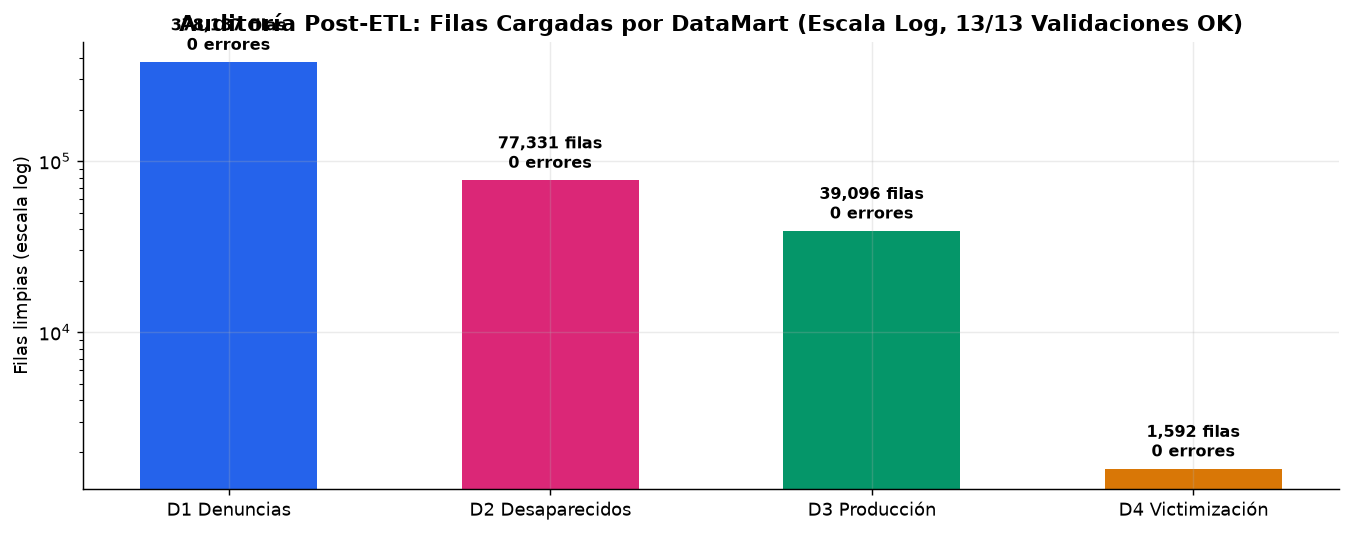

Exportación completada en: C:\Users\rodry20x\Documents\Clases-UPN\Ciclo_2026-2\BigDATA\EF_Final\EDA\EDA-Datamarts\outputs


In [9]:
# Gráfica 7: Resumen de validación de calidad post-ETL (13/13 checks OK)
fig, ax = plt.subplots(figsize=(10.5, 4.2))
datasets_lbl = ["D1 Denuncias", "D2 Desaparecidos", "D3 Producción", "D4 Victimización"]
filas_vals = resumen_dm["filas"].tolist()
bars = ax.bar(datasets_lbl, filas_vals, color=["#2563EB", "#DB2777", "#059669", "#D97706"], width=0.55)
ax.set_yscale("log")
ax.set_title("Auditoría Post-ETL: Filas Cargadas por DataMart (Escala Log, 13/13 Validaciones OK)", fontweight="bold")
ax.set_ylabel("Filas limpias (escala log)")
for b, val in zip(bars, filas_vals):
    ax.text(b.get_x() + b.get_width()/2, val * 1.18, f"{int(val):,} filas\n0 errores", ha="center", fontsize=9, fontweight="bold")
plt.tight_layout()
plt.savefig(OUT_DIR / "07_dm_auditoria_resumen.png", dpi=150, bbox_inches="tight")
plt.show()

resumen_dm_json = {
    "etapa": "DataMarts Procesados (Post-ETL)",
    "sql_server": SQL_SERVER,
    "motor": f"PySpark SQL {spark.version}",
    "total_filas_datamarts": int(resumen_dm["filas"].sum()),
    "validaciones_totales": int(len(auditoria_df)),
    "validaciones_ok": int((auditoria_df["estado"] == "OK").sum()),
    "validaciones_fallidas": int((auditoria_df["estado"] != "OK").sum()),
    "datasets": {
        "denuncias": {
            "filas": int(resumen_dm.loc[0, "filas"]),
            "total_denuncias_2018_2025": int(q1_anual["total_denuncias"].sum()),
            "modalidad_lider": str(q1_modalidad.loc[0, "modalidad"]),
            "modalidad_lider_pct": float(q1_modalidad.loc[0, "pct_participacion"]),
            "ubigeos_invalidos": 0,
            "duplicados_grano": 0,
            "es_anio_parcial_marcado": True,
        },
        "desaparecidos": {
            "filas": int(resumen_dm.loc[1, "filas"]),
            "total_casos": int(q2_kpis.loc[0, "total_casos"]),
            "menores_18": int(q2_kpis.loc[0, "menores_18"]),
            "pct_menores_18": float(q2_kpis.loc[0, "pct_menores_18"]),
            "dptos_no_canonicos": 0,
            "duplicados_grano": 0,
            "codificacion": "UTF-8 (SQL NVARCHAR)",
        },
        "produccion": {
            "filas": int(resumen_dm.loc[2, "filas"]),
            "kilos_droga_2023_2025": float(q3_anual["kilos_droga"].sum()),
            "dinero_incautado_soles_2023_2025": float(q3_anual["dinero_incautado_soles"].sum()),
            "detenidos_2023_2025": int(q3_anual["detenidos"].sum()),
            "bandas_desarticuladas_2023_2025": int(q3_anual["bandas_desarticuladas"].sum()),
            "operativos_2023_2025": int(q3_anual["operativos"].sum()),
            "unidades_medida_separadas": int(len(q3_por_unidad)),
            "meses_numericos": True,
            "duplicados_grano": 0,
        },
        "victimizacion": {
            "filas": int(resumen_dm.loc[3, "filas"]),
            "dpto_mayor_inseguridad": str(q4_dptos.iloc[0]["departamento"]),
            "mayor_inseguridad_pct": float(q4_dptos.iloc[0]["prom_inseguridad_pct"]),
            "dpto_menor_confianza": str(q4_dptos.sort_values("prom_confianza_pnp_pct").iloc[0]["departamento"]),
            "menor_confianza_pct": float(q4_dptos.sort_values("prom_confianza_pnp_pct").iloc[0]["prom_confianza_pnp_pct"]),
            "codigos_desalineados": 0,
            "ambito_separado": True,
            "es_anio_parcial_marcado": True,
        },
    },
    "cruce_departamentos_coincidentes": int(len(q5_cruzado)),
    "auditoria": auditoria_df.to_dict(orient="records"),
}

(OUT_DIR / "resumen_datamarts.json").write_text(
    json.dumps(resumen_dm_json, ensure_ascii=False, indent=2), encoding="utf-8"
)
print("Exportación completada en:", OUT_DIR)
spark.stop()
shutil.rmtree(TMP_SQL_DIR, ignore_errors=True)